## Get the entire human proteome

In [4]:
import requests
url = 'https://rest.uniprot.org/uniprotkb/stream?compressed=false&format=fasta&query=%28%28proteome%3AUP000005640%29%29'
all_fastas = requests.get(url).text

In [5]:
len(all_fastas)

37531397

In [1]:
from Bio import SeqIO 
import pandas as pd 
import numpy as np
from io import StringIO

In [13]:
records = SeqIO.parse(StringIO(all_fastas), "fasta") 
ids = [] 
descriptions = [] 
seqs = [] 
for record in records: 
    ids.append(record.id) 
    descriptions.append(record.description) 
    seqs.append(record.seq)

In [14]:
human_uniprot = pd.DataFrame({'id': ids,'description': descriptions, 'seq': seqs})

In [16]:
human_uniprot["seq"] = human_uniprot["seq"].apply(lambda s: s.__str__())

In [18]:
human_uniprot["uniprot_acc"] = human_uniprot["id"].apply(lambda s: s.split("|")[1])

In [19]:
human_uniprot.head()

,id,description,seq,uniprot_acc
0,tr|A0A075B6G3|A0A075B6G3_HUMAN,tr|A0A075B6G3|A0A075B6G3_HUMAN Dystrophin OS=H...,MLWWEEVEDCYEREDVQKKTFTKWVNAQFSKFGKQHIENLFSDLQD...,A0A075B6G3
1,tr|A0A087WV00|A0A087WV00_HUMAN,tr|A0A087WV00|A0A087WV00_HUMAN Diacylglycerol ...,MDAAGRGCHLLPLPAARGPARAPAAAAAAAASPPGPCSGAACAPSA...,A0A087WV00
2,tr|A0A087WZT3|A0A087WZT3_HUMAN,tr|A0A087WZT3|A0A087WZT3_HUMAN BOLA2-SMG1P6 re...,MELSAEYLREKLQRDLEAEHVLPSPGGVGQVRGETAASETQLGS,A0A087WZT3
3,sp|A0A087X1C5|CP2D7_HUMAN,sp|A0A087X1C5|CP2D7_HUMAN Putative cytochrome ...,MGLEALVPLAMIVAIFLLLVDLMHRHQRWAARYPPGPLPLPGLGNL...,A0A087X1C5
4,tr|A0A087X296|A0A087X296_HUMAN,tr|A0A087X296|A0A087X296_HUMAN Prostaglandin G...,MSRSLLLWFLLFLLLLPPLPVLLADPGAPTPVNPCCYYPCQHQGIC...,A0A087X296


In [20]:
human_uniprot.shape

(79740, 4)

## Subset the the human proteome that does not contain phosphosite

In [27]:
import os

In [29]:
dataroot = "../../..${SPARK_ACQUISITION_ROOT}/kinase_ml/data"
psite_animal = pd.read_pickle(os.path.join(dataroot,"pretraining","phosphosite_animal.pkl"))
psite_xl = pd.read_pickle(os.path.join(dataroot,"pretraining","phosphosite_xl.pkl"))
interaction_exp = pd.read_pickle(os.path.join(dataroot,"interactions","interaction_exp.pkl")) 
interaction_pred = pd.read_pickle(os.path.join(dataroot,"interactions","interaction_pred.pkl"))

In [38]:
!pip install upsetplot
import upsetplot

  Preparing metadata (setup.py) ... done
  Created wheel for upsetplot: filename=UpSetPlot-0.6.1-py3-none-any.whl size=19088 sha256=b7a38b5a7d809cf664c6864bd196d3c51a87d9f15bab6b3df0a253cc5df2e66d
  Stored in directory: /root/.cache/pip/wheels/a9/6f/4f/599b066020d1a39d7c183753064f20de6ce437b704472119f9
Successfully built upsetplot
--- Logging error ---
Traceback (most recent call last):
  File "/usr/local/lib/python3.8/dist-packages/pip/_internal/utils/logging.py", line 177, in emit
    self.console.print(renderable, overflow="ignore", crop=False, style=style)
  File "/usr/local/lib/python3.8/dist-packages/pip/_vendor/rich/console.py", line 1752, in print
    extend(render(renderable, render_options))
  File "/usr/local/lib/python3.8/dist-packages/pip/_vendor/rich/console.py", line 1390, in render
    for render_output in iter_render:
  File "/usr/local/lib/python3.8/dist-packages/pip/_internal/utils/logging.py", line 134, in __rich_console__
    for line in lines:
  File "/usr/local/l

{'matrix': <AxesSubplot:>,
 'shading': <AxesSubplot:>,
 'totals': <AxesSubplot:>,
 'intersections': <AxesSubplot:ylabel='Intersection size'>}

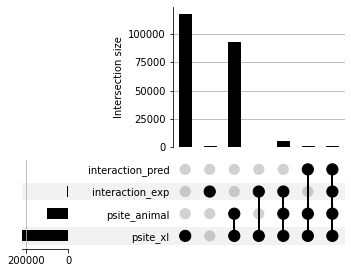

In [43]:
ks_dict = {"psite_animal":list(set(psite_animal["uniprot"].drop_duplicates())),\
          "psite_xl":list(set(psite_xl["uniprot"].drop_duplicates())),\
          "interaction_exp": list(set(interaction_exp["substrate"].drop_duplicates())),\
          "interaction_pred":list(set(interaction_pred["substrate_acc"].drop_duplicates()))}
upset_data_sub = upsetplot.from_contents(ks_dict)
upsetplot.plot(upset_data_sub)

In [45]:
psite_all = list((list(set(psite_xl["uniprot"].drop_duplicates())) + list(set(interaction_exp["substrate"].drop_duplicates()))))

{'matrix': <AxesSubplot:>,
 'shading': <AxesSubplot:>,
 'totals': <AxesSubplot:>,
 'intersections': <AxesSubplot:ylabel='Intersection size'>}

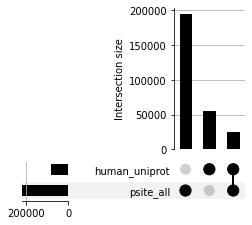

In [50]:
ks_dict = {"human_uniprot":list(set(human_uniprot["uniprot_acc"].drop_duplicates())),\
          "psite_all":list(np.unique(psite_all))}
upset_data_sub = upsetplot.from_contents(ks_dict)
upsetplot.plot(upset_data_sub)

In [51]:
human_uniprot_background = human_uniprot.loc[~human_uniprot["uniprot_acc"].isin(psite_all),:]

In [52]:
human_uniprot_background.shape

(54839, 4)

## Sample S/T/Y surrounding environment as negative samples

In [100]:
def get_background_AA(seq,AA):
    search_start = 15
    res_s = []
    while (len(seq)>2*search_start + 1):
        try:
            first_res_ind = seq[search_start:].index(AA)
            psite_ind = search_start + first_res_ind
            frag = seq[psite_ind-15:psite_ind+16]
            res_s.append(frag)
            seq = seq[psite_ind+16:]
        except:
            break
    return res_s
    

In [101]:
res_s_all = []
for i in range(human_uniprot_background.shape[0]):
    seq = human_uniprot_background["seq"].iloc[i]
    res_s = get_background_AA(seq,'S')
    res_s_all.extend(res_s)

In [103]:
res_t_all = []
for i in range(human_uniprot_background.shape[0]):
    seq = human_uniprot_background["seq"].iloc[i]
    res_t = get_background_AA(seq,'T')
    res_t_all.extend(res_t)

In [104]:
res_y_all = []
for i in range(human_uniprot_background.shape[0]):
    seq = human_uniprot_background["seq"].iloc[i]
    res_y = get_background_AA(seq,'Y')
    res_y_all.extend(res_y)

In [105]:
len(res_s_all)

323046

In [106]:
len(res_t_all)

285196

In [107]:
len(res_y_all)

197400

In [108]:
import pickle

In [109]:
with open(os.path.join(dataroot,"interactions","background_sub_s.pkl"), 'wb') as f:
    pickle.dump(res_s_all, f)

In [110]:
with open(os.path.join(dataroot,"interactions","background_sub_t.pkl"), 'wb') as f:
    pickle.dump(res_t_all, f)

In [111]:
with open(os.path.join(dataroot,"interactions","background_sub_y.pkl"), 'wb') as f:
    pickle.dump(res_y_all, f)

## Simplest negative sample generation by kinase-background_sub pairs

In [62]:
from Bio import SeqIO 
import pandas as pd 
import numpy as np
from io import StringIO
import pickle
import os
import random
dataroot = "../../..${SPARK_ACQUISITION_ROOT}/kinase_ml/data"

In [63]:
interations = pd.read_pickle("${SPARK_ACQUISITION_ROOT}/kinase_ml/data/interactions/interaction_exp_cleaned_220923.pkl")

In [64]:
interations = interations.reset_index().iloc[:,1:]

In [65]:
interations.head(1)

,substrate,kinase,p_ind,p_aa,substrate_seq,kinase_seq,kinase_pfam,kinase_interpro,domain_cc,domain_ft,protein_families,kinase_flag,kinase_coord,valid_check
0,P34901,Q05655,183,S,MAPVCLFAPLLLLLLGGFPVAPGESIRETEVIDPQDLLEGRYFSGA...,MAPFLRIAFNSYELGSLQAEDEANQPFCAVKMKEALSTERGKTLVQ...,PF00130;PF00069;PF00433;,IPR000961;IPR046349;IPR000008;IPR035892;IPR020...,"DOMAIN: The C1 domain, containing the phorbol ...","DOMAIN 1..106; /note=""C2""; /evidence=""ECO:00...","Protein kinase superfamily, AGC Ser/Thr protei...",pk,"[[349, 603]]",valid


In [66]:
interations["substrate_seq"].iloc[0][182]

'S'

In [67]:
interations.groupby("p_aa").count()

,substrate,kinase,p_ind,substrate_seq,kinase_seq,kinase_pfam,kinase_interpro,domain_cc,domain_ft,protein_families,kinase_flag,kinase_coord,valid_check
p_aa,,,,,,,,,,,,,
H,1,1,1,1,1,1,1,0,1,1,1,1,1
I,1,1,1,1,1,1,1,0,1,1,1,1,1
R,2,2,2,2,2,2,2,0,2,2,2,2,2
S,18625,18625,18625,18625,18625,18618,18625,6629,18625,18194,18625,18625,18625
T,6553,6553,6553,6553,6553,6531,6553,2697,6553,6397,6553,6553,6553
Y,4716,4716,4716,4716,4716,4716,4716,2346,4716,4611,4716,4716,4716


In [68]:
interations = interations.loc[(interations["p_aa"] == 'S')|(interations["p_aa"] == 'T')|(interations["p_aa"] == 'Y'),:].reset_index()

In [69]:
interations.groupby("p_aa").count()

,index,substrate,kinase,p_ind,substrate_seq,kinase_seq,kinase_pfam,kinase_interpro,domain_cc,domain_ft,protein_families,kinase_flag,kinase_coord,valid_check
p_aa,,,,,,,,,,,,,,
S,18625,18625,18625,18625,18625,18625,18618,18625,6629,18625,18194,18625,18625,18625
T,6553,6553,6553,6553,6553,6553,6531,6553,2697,6553,6397,6553,6553,6553
Y,4716,4716,4716,4716,4716,4716,4716,4716,2346,4716,4611,4716,4716,4716


In [52]:
interations__e2e = interations.loc[:,["substrate_seq","kinase_seq","p_ind","p_aa","kinase_coord"]]

In [53]:
with open(os.path.join(dataroot,"interactions","background_sub_s.pkl"), 'rb') as f:
    res_s_all = pickle.load(f)
with open(os.path.join(dataroot,"interactions","background_sub_t.pkl"), 'rb') as f:
    res_t_all = pickle.load(f)
with open(os.path.join(dataroot,"interactions","background_sub_y.pkl"), 'rb') as f:
    res_y_all = pickle.load(f)

In [54]:
interations__e2e['label'] = 1

In [55]:
res = []
num_neg = 10
for i in range(interations.shape[0]):
    kin_seq = interations.loc[i,"kinase_seq"]
    kin_coord = interations.loc[i,"kinase_coord"]
    if (interations.loc[i,"p_aa"] == 'S'):
        bg_seqs = random.sample(res_s_all,k = num_neg)
        for bg_seq in bg_seqs:
            res.append({"substrate_seq": bg_seq, \
             "kinase_seq":kin_seq, \
             "p_ind": 16, \
             "p_aa":'S', \
             "kinase_coord": kin_coord})
    elif (interations.loc[i,"p_aa"] == 'T'):
        bg_seqs = random.sample(res_t_all,k = num_neg)
        for bg_seq in bg_seqs:
            res.append({"substrate_seq": bg_seq, \
             "kinase_seq":kin_seq, \
             "p_ind": 16, \
             "p_aa":'T', \
             "kinase_coord": kin_coord})
    elif (interations.loc[i,"p_aa"] == 'Y'):
        bg_seqs = random.sample(res_y_all,k = num_neg)
        for bg_seq in bg_seqs:
            res.append({"substrate_seq": bg_seq, \
             "kinase_seq":kin_seq, \
             "p_ind": 16, \
             "p_aa":'Y', \
             "kinase_coord": kin_coord})
neg_interations = pd.DataFrame(res)
neg_interations['label'] = 0
interations_e2e_np = pd.concat([interations__e2e,neg_interations],axis = 0).reset_index().iloc[:,1:]
interations_e2e_np.to_pickle("${SPARK_ACQUISITION_ROOT}/kinase_ml/data/interactions/interations_e2e_10n1p.pkl")

In [56]:
res = []
num_neg = 5
for i in range(interations.shape[0]):
    kin_seq = interations.loc[i,"kinase_seq"]
    kin_coord = interations.loc[i,"kinase_coord"]
    if (interations.loc[i,"p_aa"] == 'S'):
        bg_seqs = random.sample(res_s_all,k = num_neg)
        for bg_seq in bg_seqs:
            res.append({"substrate_seq": bg_seq, \
             "kinase_seq":kin_seq, \
             "p_ind": 16, \
             "p_aa":'S', \
             "kinase_coord": kin_coord})
    elif (interations.loc[i,"p_aa"] == 'T'):
        bg_seqs = random.sample(res_t_all,k = num_neg)
        for bg_seq in bg_seqs:
            res.append({"substrate_seq": bg_seq, \
             "kinase_seq":kin_seq, \
             "p_ind": 16, \
             "p_aa":'T', \
             "kinase_coord": kin_coord})
    elif (interations.loc[i,"p_aa"] == 'Y'):
        bg_seqs = random.sample(res_y_all,k = num_neg)
        for bg_seq in bg_seqs:
            res.append({"substrate_seq": bg_seq, \
             "kinase_seq":kin_seq, \
             "p_ind": 16, \
             "p_aa":'Y', \
             "kinase_coord": kin_coord})
neg_interations = pd.DataFrame(res)
neg_interations['label'] = 0
interations_e2e_np = pd.concat([interations__e2e,neg_interations],axis = 0).reset_index().iloc[:,1:]
interations_e2e_np.to_pickle("${SPARK_ACQUISITION_ROOT}/kinase_ml/data/interactions/interations_e2e_5n1p.pkl")

In [57]:
res = []
num_neg = 2
for i in range(interations.shape[0]):
    kin_seq = interations.loc[i,"kinase_seq"]
    kin_coord = interations.loc[i,"kinase_coord"]
    if (interations.loc[i,"p_aa"] == 'S'):
        bg_seqs = random.sample(res_s_all,k = num_neg)
        for bg_seq in bg_seqs:
            res.append({"substrate_seq": bg_seq, \
             "kinase_seq":kin_seq, \
             "p_ind": 16, \
             "p_aa":'S', \
             "kinase_coord": kin_coord})
    elif (interations.loc[i,"p_aa"] == 'T'):
        bg_seqs = random.sample(res_t_all,k = num_neg)
        for bg_seq in bg_seqs:
            res.append({"substrate_seq": bg_seq, \
             "kinase_seq":kin_seq, \
             "p_ind": 16, \
             "p_aa":'T', \
             "kinase_coord": kin_coord})
    elif (interations.loc[i,"p_aa"] == 'Y'):
        bg_seqs = random.sample(res_y_all,k = num_neg)
        for bg_seq in bg_seqs:
            res.append({"substrate_seq": bg_seq, \
             "kinase_seq":kin_seq, \
             "p_ind": 16, \
             "p_aa":'Y', \
             "kinase_coord": kin_coord})
neg_interations = pd.DataFrame(res)
neg_interations['label'] = 0
interations_e2e_np = pd.concat([interations__e2e,neg_interations],axis = 0).reset_index().iloc[:,1:]
interations_e2e_np.to_pickle("${SPARK_ACQUISITION_ROOT}/kinase_ml/data/interactions/interations_e2e_2n1p_2.pkl")

In [58]:
res = []
num_neg = 1
for i in range(interations.shape[0]):
    kin_seq = interations.loc[i,"kinase_seq"]
    kin_coord = interations.loc[i,"kinase_coord"]
    if (interations.loc[i,"p_aa"] == 'S'):
        bg_seqs = random.sample(res_s_all,k = num_neg)
        for bg_seq in bg_seqs:
            res.append({"substrate_seq": bg_seq, \
             "kinase_seq":kin_seq, \
             "p_ind": 16, \
             "p_aa":'S', \
             "kinase_coord": kin_coord})
    elif (interations.loc[i,"p_aa"] == 'T'):
        bg_seqs = random.sample(res_t_all,k = num_neg)
        for bg_seq in bg_seqs:
            res.append({"substrate_seq": bg_seq, \
             "kinase_seq":kin_seq, \
             "p_ind": 16, \
             "p_aa":'T', \
             "kinase_coord": kin_coord})
    elif (interations.loc[i,"p_aa"] == 'Y'):
        bg_seqs = random.sample(res_y_all,k = num_neg)
        for bg_seq in bg_seqs:
            res.append({"substrate_seq": bg_seq, \
             "kinase_seq":kin_seq, \
             "p_ind": 16, \
             "p_aa":'Y', \
             "kinase_coord": kin_coord})
neg_interations = pd.DataFrame(res)
neg_interations['label'] = 0
interations_e2e_np = pd.concat([interations__e2e,neg_interations],axis = 0).reset_index().iloc[:,1:]
interations_e2e_np.to_pickle("${SPARK_ACQUISITION_ROOT}/kinase_ml/data/interactions/interations_e2e_1n1p.pkl")

In [59]:
dat = pd.read_pickle("${SPARK_ACQUISITION_ROOT}/kinase_ml/data/interactions/interations_e2e_1n1p.pkl")

In [60]:
dat.loc[dat["label"]==0,:].groupby("p_aa").count()

,substrate_seq,kinase_seq,p_ind,kinase_coord,label
p_aa,,,,,
S,18625,18625,18625,18625,18625
T,6553,6553,6553,6553,6553
Y,4716,4716,4716,4716,4716


## Get family and subfamily of kinase for generating negative samples from un-related substrates

1. Get the kinases with good documentation of kinase family and group
2. For the unmapped: search for the existance of a human gene that share the same name and get from human ortholog
3. For the further unmapped: search manually mapping to the human kinase atlas classification

In [70]:
unique_kinase_class = interations.loc[:,["kinase","protein_families"]].drop_duplicates()

In [71]:
"superfamily" in "Protein kinase superfamily"

True

In [72]:
def get_class(class_name,s):
    s_arr = str(s).split(",")
    try:
        s_class = [elem for elem in s_arr if class_name in elem][0]
#         print(s_class)
        s_res = s_class.split(" " + class_name)[0]
        return s_res
    except: 
        return ""

In [73]:
unique_kinase_class["superfamily"] = unique_kinase_class["protein_families"].apply(lambda s: get_class("superfamily",s))

In [74]:
unique_kinase_class["pk_family"] = unique_kinase_class["protein_families"].apply(lambda s: get_class("protein kinase family",s)[1:])

In [75]:
unique_kinase_class["pk_subfamily"] = unique_kinase_class["protein_families"].apply(lambda s: get_class("subfamily",s)[1:])

In [76]:
unique_kinase_class["pk_family_ST"] = unique_kinase_class["pk_family"].apply(lambda s: get_class("Ser/Thr",s))

In [24]:
unique_kinase_class.to_csv("${SPARK_ACQUISITION_ROOT}/kinase_ml/data/interactions/unique_kinase_families.csv")

In [90]:
unique_kinase_class.groupby(["pk_family","pk_subfamily"]).count().to_csv("kinase_class_stats.csv")

In [94]:
unmapped_kinases = unique_kinase_class.loc[unique_kinase_class["pk_family"]=="",:]

In [96]:
unmapped_kinases.to_csv("kinase_wo_family.csv")

In [121]:
unmapped_kinases = pd.read_csv("./kinase_wo_family_organism.tsv",sep = "\t")

In [129]:
import requests
import io
def get_uniprot_entry(acc,species):
    url = "https://rest.uniprot.org/uniprotkb/search?query="+acc + "%20" +species  + "+AND+gene:"+acc +"&fields=id,protein_families&format=tsv"
    print(url)
    try:
        urlData = requests.get(url).content
        rawData = pd.read_csv(io.StringIO(urlData.decode('utf-8')),sep = '\t')
        rawData = rawData.iloc[[0],:]
        rawData["gene"] = acc
    except:
        rawData = pd.DataFrame()
    return rawData

In [128]:
unmapped_kinases["gene"] = unmapped_kinases["Gene Names"].apply(lambda s: s.split(" ")[0])

In [130]:
res_ls = []
for i in range(unmapped_kinases.shape[0]):
    res = get_uniprot_entry(unmapped_kinases["gene"].iloc[i],"homo sapiens")
    res_ls.append(res)

https://rest.uniprot.org/uniprotkb/search?query=camk1%20homo sapiens+AND+gene:camk1&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=Irak1%20homo sapiens+AND+gene:Irak1&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=PRKCI%20homo sapiens+AND+gene:PRKCI&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=Sik2%20homo sapiens+AND+gene:Sik2&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=Hipk2%20homo sapiens+AND+gene:Hipk2&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=PAK3%20homo sapiens+AND+gene:PAK3&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=TP53RK%20homo sapiens+AND+gene:TP53RK&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=RET/PTC2%20homo sapiens+AND+gene:RET/PTC2&fields=id,protein_families&format=tsv
https://rest.uniprot

https://rest.uniprot.org/uniprotkb/search?query=Egfr%20homo sapiens+AND+gene:Egfr&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=EIF2AK2%20homo sapiens+AND+gene:EIF2AK2&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=EIF2AK1%20homo sapiens+AND+gene:EIF2AK1&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=EIF2AK3%20homo sapiens+AND+gene:EIF2AK3&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=PAK2%20homo sapiens+AND+gene:PAK2&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=PASK%20homo sapiens+AND+gene:PASK&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=NUAK1%20homo sapiens+AND+gene:NUAK1&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=PASK%20homo sapiens+AND+gene:PASK&fields=id,protein_families&format=tsv
https://rest.uniprot

https://rest.uniprot.org/uniprotkb/search?query=Epha4%20homo sapiens+AND+gene:Epha4&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=DAPK1%20homo sapiens+AND+gene:DAPK1&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=MAPK13%20homo sapiens+AND+gene:MAPK13&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=MAPKAPK2%20homo sapiens+AND+gene:MAPKAPK2&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=MAPK12%20homo sapiens+AND+gene:MAPK12&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=CDK1%20homo sapiens+AND+gene:CDK1&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=Gucy2d%20homo sapiens+AND+gene:Gucy2d&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=Gucy2e%20homo sapiens+AND+gene:Gucy2e&fields=id,protein_families&format=tsv
https://rest

https://rest.uniprot.org/uniprotkb/search?query=CAMK1%20homo sapiens+AND+gene:CAMK1&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=SIK1%20homo sapiens+AND+gene:SIK1&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=HIPK4%20homo sapiens+AND+gene:HIPK4&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=CDK5%20homo sapiens+AND+gene:CDK5&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=NUAK1%20homo sapiens+AND+gene:NUAK1&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=VRK1%20homo sapiens+AND+gene:VRK1&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=CHEK2%20homo sapiens+AND+gene:CHEK2&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=MAPKAPK5%20homo sapiens+AND+gene:MAPKAPK5&fields=id,protein_families&format=tsv
https://rest.uniprot.org

https://rest.uniprot.org/uniprotkb/search?query=MAPK14%20homo sapiens+AND+gene:MAPK14&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=STK16%20homo sapiens+AND+gene:STK16&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=Pask%20homo sapiens+AND+gene:Pask&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=PASK%20homo sapiens+AND+gene:PASK&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=PASK%20homo sapiens+AND+gene:PASK&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=PASK%20homo sapiens+AND+gene:PASK&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=CDK2%20homo sapiens+AND+gene:CDK2&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=PKDCC%20homo sapiens+AND+gene:PKDCC&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprot

https://rest.uniprot.org/uniprotkb/search?query=TSSK4%20homo sapiens+AND+gene:TSSK4&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=TSSK4%20homo sapiens+AND+gene:TSSK4&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=Tssk4%20homo sapiens+AND+gene:Tssk4&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=TBK1%20homo sapiens+AND+gene:TBK1&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=TBK1%20homo sapiens+AND+gene:TBK1&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=CDK5%20homo sapiens+AND+gene:CDK5&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=NUAK1%20homo sapiens+AND+gene:NUAK1&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=VRK1%20homo sapiens+AND+gene:VRK1&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprot

https://rest.uniprot.org/uniprotkb/search?query=CDK1%20homo sapiens+AND+gene:CDK1&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=NEK1%20homo sapiens+AND+gene:NEK1&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=PAK5%20homo sapiens+AND+gene:PAK5&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=PINK1%20homo sapiens+AND+gene:PINK1&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=PINK1%20homo sapiens+AND+gene:PINK1&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=PINK1%20homo sapiens+AND+gene:PINK1&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=JEQ12_010148%20homo sapiens+AND+gene:JEQ12_010148&fields=id,protein_families&format=tsv
https://rest.uniprot.org/uniprotkb/search?query=MKNK2%20homo sapiens+AND+gene:MKNK2&fields=id,protein_families&format=tsv
https://rest.uni

In [133]:
sum([len(res)==0 for res in res_ls])

19

In [150]:
unmapped_kinases["protein_family"] = ""
for i in range(unmapped_kinases.shape[0]):
    try:
        unmapped_kinases["protein_family"].iloc[i] = res_ls[i]["Protein families"].iloc[0]
    except:
        print(i)

7
12
16
17
20
52
54
59
60
76
103
143
171
178
179
180
182
216
244
269
292
414
432


/usr/local/lib/python3.8/dist-packages/pandas/core/indexing.py:670: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iloc._setitem_with_indexer(indexer, value)


In [153]:
unmapped_kinases.loc[unmapped_kinases["protein_family"] == "",:].to_csv("./unmapped_kinases_2.csv")

In [161]:
unmapped_kinases = unmapped_kinases.loc[:,["From","protein_family"]]
unmapped_kinases.columns = ["kinase","protein_families"]

In [163]:
unmapped_kinases["superfamily"] = unmapped_kinases["protein_families"].apply(lambda s: get_class("superfamily",s))

In [164]:
unmapped_kinases["pk_family"] = unmapped_kinases["protein_families"].apply(lambda s: get_class("protein kinase family",s)[1:])

In [165]:
unmapped_kinases["pk_subfamily"] = unmapped_kinases["protein_families"].apply(lambda s: get_class("subfamily",s)[1:])

In [166]:
unmapped_kinases["pk_family_ST"] = unmapped_kinases["pk_family"].apply(lambda s: get_class("Ser/Thr",s))

In [178]:
kinase_mapped_2 = pd.concat([unique_kinase_class.loc[unique_kinase_class["pk_family"]!="",:],
unmapped_kinases.loc[unmapped_kinases["pk_family"]!="",:]])

In [187]:
# merge in the third matched set and get stats
unique_kinase_3 = pd.read_csv("./unmapped_kinases_2.csv")

In [190]:
unique_kinase_3 = unique_kinase_3.loc[:,["kinase","superfamily","pk_family","pk_subfamily"]]
kinase_mapped_2 = kinase_mapped_2.loc[:,["kinase","superfamily","pk_family","pk_subfamily"]]

In [191]:
kinase_mapped_3 = pd.concat([unique_kinase_3,kinase_mapped_2])

In [194]:
kinase_mapped_3.loc[kinase_mapped_3["pk_family"]!="",:].groupby(["pk_family","pk_subfamily"]).count().to_csv("kinase_class_stats.csv")

In [196]:
kinase_mapped_3.groupby(["pk_family"]).count()

,kinase,superfamily,pk_subfamily
pk_family,,,
ADCK,1,1,1
AGC Ser/Thr,282,282,282
CAMK Ser/Thr,302,302,302
CK1 Ser/Thr,55,55,55
CMGC Ser/Thr,386,386,386
DK/BCKDK,34,34,34
NEK Ser/Thr,28,28,28
STE Ser/Thr,187,187,187
Ser/Thr,318,318,318


In [199]:
kinase_mapped_3.loc[kinase_mapped_3["pk_family"]=="Tyr",:].groupby("pk_subfamily").count()

,kinase,superfamily,pk_family
pk_subfamily,,,
,120,120,120
ABL,6,6,6
AXL/UFO,5,5,5
BRK/PTK6/SIK,2,2,2
CSF-1/PDGF receptor,17,17,17
CSK,8,8,8
DDR,1,1,1
EGF receptor,19,19,19
Ephrin receptor,23,23,23


In [204]:
print("number of total interactions")
print(interations.shape[0])

print("number of interactions with known kinase class")
print(interations.loc[interations["kinase"].isin(kinase_mapped_3["kinase"]),:].shape[0])

number of total interactions
29894
number of interactions with known kinase class
29840


In [205]:
interaction_classed = interations.loc[interations["kinase"].isin(kinase_mapped_3["kinase"]),:]

In [210]:
interaction_classed = pd.merge(interaction_classed,kinase_mapped_3,on = "kinase").iloc[:,1:]

In [212]:
interaction_classed.to_pickle("${SPARK_ACQUISITION_ROOT}/kinase_ml/data/interactions/interaction_classed_221017.pkl")

### Generate Negative Kinase interaction pair by connecting substrates of the same p_aa but different broader family
    - for Ser/Thr, get it from a different family
    - for Tyr, get it from a different subfamily

#### Get stats on psite's #kinase family

In [252]:
unique_psites = interaction_classed.loc[:,["substrate","p_ind"]].drop_duplicates()
def count_family(s):
#     print(s["substrate"])
    return interaction_classed.loc[(interaction_classed["substrate"]==s["substrate"])&(interaction_classed["p_ind"]==s["p_ind"]),["pk_family"]].drop_duplicates().shape[0]

unique_psites["num_fam"] = unique_psites.apply(lambda s: count_family(s), axis = 1)

In [288]:
unique_psites.loc[(unique_psites["num_fam"]>3),:].shape[0]

55

#### An example of substrate being phosphorylated by many kinase families

In [266]:
interaction_classed.loc[(interaction_classed["substrate"]=="P31749")&(interaction_classed["p_ind"]==473),"pk_family"]

377       AGC Ser/Thr
2766     CAMK Ser/Thr
4932     CMGC Ser/Thr
12627     AGC Ser/Thr
13922     AGC Ser/Thr
14916         Ser/Thr
16364    CAMK Ser/Thr
16777     TKL Ser/Thr
18573     TKL Ser/Thr
19130             Tyr
19140             Tyr
19872         Ser/Thr
29685        DK/BCKDK
Name: pk_family, dtype: object

#### Remove 55 psites with >3 families of kinase

In [291]:
for index, s in unique_psites.loc[(unique_psites["num_fam"]>3),:].iterrows():
    indexDrop = interaction_classed[(interaction_classed['substrate'] == s["substrate"])&(interaction_classed['p_ind'] == s["p_ind"]) ].index
#     print(indexDrop)
    interaction_classed = interaction_classed.drop(indexDrop)


## Negative Pairs Generation 

In [296]:
res = []
num_neg = 1

for i in interaction_classed.index:
    kin_seq = interations.loc[i,"kinase_seq"]
    kin_coord = interations.loc[i,"kinase_coord"]
    p_aa = interaction_classed.loc[i,"p_aa"] 
    s = interations.loc[i,:]
    pk_fam = interaction_classed.loc[(interaction_classed["substrate"]==s["substrate"])&(interaction_classed["p_ind"]==s["p_ind"]),"pk_family"].drop_duplicates()
    subfam = interaction_classed.loc[(interaction_classed["substrate"]==s["substrate"])&(interaction_classed["p_ind"]==s["p_ind"]),"pk_subfamily"].drop_duplicates()
    if (p_aa == 'S'):
        bg_seqs = interaction_classed.loc[(~interaction_classed["pk_family"].isin(pk_fam))& \
                                          (interaction_classed["pk_family"]!="Tyr")&
                                          (interaction_classed["p_aa"]==p_aa), \
                        :].sample(num_neg)
        for index,bg_seq in bg_seqs.iterrows():
            res.append({"substrate_seq": bg_seq["substrate_seq"], \
             "kinase_seq":kin_seq, \
             "p_ind": bg_seq["p_ind"], \
             "p_aa":bg_seq["p_aa"], \
             "kinase_coord": kin_coord})
    elif (p_aa == 'T'):
        bg_seqs = interaction_classed.loc[(~interaction_classed["pk_family"].isin(pk_fam))& \
                                          (interaction_classed["pk_family"]!="Tyr")&
                                          (interaction_classed["p_aa"]==p_aa), \
                        :].sample(num_neg)
        for index,bg_seq in bg_seqs.iterrows():
            res.append({"substrate_seq": bg_seq["substrate_seq"], \
             "kinase_seq":kin_seq, \
             "p_ind": bg_seq["p_ind"], \
             "p_aa":bg_seq["p_aa"], \
             "kinase_coord": kin_coord})
    elif (p_aa == 'Y'):
        bg_seqs = interaction_classed.loc[(interaction_classed["pk_family"]=="Tyr")& \
                                          (~interaction_classed["pk_subfamily"].isin(subfam))&
                                          (interaction_classed["p_aa"]==p_aa), \
                        :].sample(num_neg)
        for index,bg_seq in bg_seqs.iterrows():
            res.append({"substrate_seq": bg_seq["substrate_seq"], \
             "kinase_seq":kin_seq, \
             "p_ind": bg_seq["p_ind"], \
             "p_aa":bg_seq["p_aa"], \
             "kinase_coord": kin_coord})

In [298]:
interations__e2e_classed = interaction_classed.loc[:,["substrate_seq","kinase_seq","p_ind","p_aa","kinase_coord"]]
interations__e2e_classed['label'] = 1

In [299]:
neg_interations_classed = pd.DataFrame(res)
neg_interations_classed['label'] = 0
interations_e2e_np_classed = pd.concat([interations__e2e_classed,neg_interations_classed],axis = 0).reset_index().iloc[:,1:]


In [301]:
interations_e2e_np_classed.groupby(["p_aa","label"]).count()

substrate_seq  kinase_seq  p_ind  kinase_coord
p_aa label                                                
S    0              18130       18130  18130         18130
     1              18130       18130  18130         18130
T    0               6466        6466   6466          6466
     1               6466        6466   6466          6466
Y    0               4673        4673   4673          4673
     1               4673        4673   4673          4673

In [302]:
interations_e2e_np_classed.to_pickle("${SPARK_ACQUISITION_ROOT}/kinase_ml/data/interactions/interations_e2e_1n1p_classed.pkl")


In [305]:
interations_e2e_np_classed_random = pd.concat([interations_e2e_np_classed,interations_e2e_np],axis = 0).reset_index().iloc[:,1:]
interations_e2e_np_classed_random.to_pickle("${SPARK_ACQUISITION_ROOT}/kinase_ml/data/interactions/interations_e2e_1n1p_classed_random.pkl")

In [306]:
interations_e2e_np_classed_random.groupby(['p_aa','label']).count()

substrate_seq  kinase_seq  p_ind  kinase_coord
p_aa label                                                
S    0              36755       36755  36755         36755
     1              36755       36755  36755         36755
T    0              13019       13019  13019         13019
     1              13019       13019  13019         13019
Y    0               9389        9389   9389          9389
     1               9389        9389   9389          9389

## Opening Question:
1. Why does a small number of tyr kinase has "S/T" psite and vice versa, even with literature/experimental support?
    - maybe should drop these
    - should also curate this in the naive-negative interaction dataset
2. Exclude the substrates that occur in more than 3 families?